# Dissecting Whisper

[Whisper](https://arxiv.org/abs/2212.04356) (Radford et al. 2022, OpenAI) is a speech recognizer trained on 680 000
hours of audio with transcripts collected from the web, in 99 languages. Unlike wav2vec2 (see the Wav2Vec2 notebook),
which is an encoder that produces one vector per frame, Whisper is an **encoder–decoder Transformer**: the encoder
reads a spectrogram, and the decoder writes the transcript one token at a time.

This notebook takes the pre-trained `openai/whisper-base` from the `transformers` library apart with PyTorch
introspection — printing modules, counting parameters, and recording the shape of every tensor that flows through it —
and plots what the main blocks do with a real recording.

As with wav2vec2, everything is built from a handful of basic blocks: **1D convolutions, layer norms, GELU activations,
dense (linear) layers, embeddings, and multi-head attention** — here in three flavours: self-attention in the encoder,
masked self-attention and cross-attention in the decoder.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
import torch
from transformers import WhisperForConditionalGeneration, WhisperProcessor
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
torch.manual_seed(0)
%config InlineBackend.figure_format = 'retina'

model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-base").eval()
processor = WhisperProcessor.from_pretrained("openai/whisper-base")
config = model.config

# one color per kind of basic block, used in all plots below
COLORS = {"conv": "#2a78d6", "norm": "#eb6834", "attention": "#1baf7a", "dense": "#eda100", "activation": "#e87ba4",
          "embedding": "#008300"}

## 1. The module tree

`print(model)` shows the nested `torch.nn.Module`s. PyTorch already collapses identical repeated layers
(e.g. `(0-5): 6 x WhisperEncoderLayer`). Dropout is applied with function calls here, so it doesn't show up as modules.

In [2]:
print(model)

WhisperForConditionalGeneration(
  (model): WhisperModel(
    (encoder): WhisperEncoder(
      (conv1): Conv1d(80, 512, kernel_size=(3,), stride=(1,), padding=(1,))
      (conv2): Conv1d(512, 512, kernel_size=(3,), stride=(2,), padding=(1,))
      (embed_positions): Embedding(1500, 512)
      (layers): ModuleList(
        (0-5): 6 x WhisperEncoderLayer(
          (self_attn): WhisperAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=False)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=512, out_features=2048, bias=True)
          (fc2): Linear(in_features=2048, out_features=512, bias=True)
   

The model has three parts:

1. `model.encoder` — two convolutions over a log-mel spectrogram, a positional embedding, and 6 Transformer layers;
2. `model.decoder` — a token embedding, a positional embedding, and 6 Transformer layers that also attend to the encoder output;
3. `proj_out` — a dense layer from 512 dimensions to scores for each of the 51 865 tokens of the vocabulary.

The configuration values that determine the architecture:

In [3]:
{k: getattr(config, k) for k in [
    "num_mel_bins", "max_source_positions", "d_model", "encoder_layers", "encoder_attention_heads", "encoder_ffn_dim",
    "decoder_layers", "decoder_attention_heads", "decoder_ffn_dim", "max_target_positions", "vocab_size",
    "activation_function", "tie_word_embeddings",
]}

{'num_mel_bins': 80,
 'max_source_positions': 1500,
 'd_model': 512,
 'encoder_layers': 6,
 'encoder_attention_heads': 8,
 'encoder_ffn_dim': 2048,
 'decoder_layers': 6,
 'decoder_attention_heads': 8,
 'decoder_ffn_dim': 2048,
 'max_target_positions': 448,
 'vocab_size': 51865,
 'activation_function': 'gelu',
 'tie_word_embeddings': True}

### Where the parameters are

`proj_out` has no parameters of its own: its weight matrix *is* the token embedding matrix (`tie_word_embeddings`),
used once to turn tokens into vectors and once, transposed, to turn vectors back into token scores.

In [4]:
print("proj_out shares the token embedding:", model.proj_out.weight is model.model.decoder.embed_tokens.weight)


def n_params(module: torch.nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())  # parameters() lists shared tensors once


encoder, decoder = model.model.encoder, model.model.decoder
stages = {
    "encoder.conv1, conv2": [encoder.conv1, encoder.conv2],
    "encoder.embed_positions": [encoder.embed_positions],
    "encoder.layers (6x)": [encoder.layers],
    "encoder.layer_norm": [encoder.layer_norm],
    "decoder.embed_tokens (= proj_out)": [decoder.embed_tokens],
    "decoder.embed_positions": [decoder.embed_positions],
    "decoder.layers (6x)": [decoder.layers],
    "decoder.layer_norm": [decoder.layer_norm],
}
table = pd.DataFrame({"parameters": {name: sum(n_params(m) for m in ms) for name, ms in stages.items()}})
table.loc["total"] = n_params(model)
table["share"] = (table["parameters"] / n_params(model)).map("{:.1%}".format)
table

proj_out shares the token embedding: True


,parameters,share
"encoder.conv1, conv2",910336,1.3%
encoder.embed_positions,768000,1.1%
encoder.layers (6x),18911232,26.1%
encoder.layer_norm,1024,0.0%
decoder.embed_tokens (= proj_out),26554880,36.6%
decoder.embed_positions,229376,0.3%
decoder.layers (6x),25218048,34.7%
decoder.layer_norm,1024,0.0%
total,72593920,100.0%


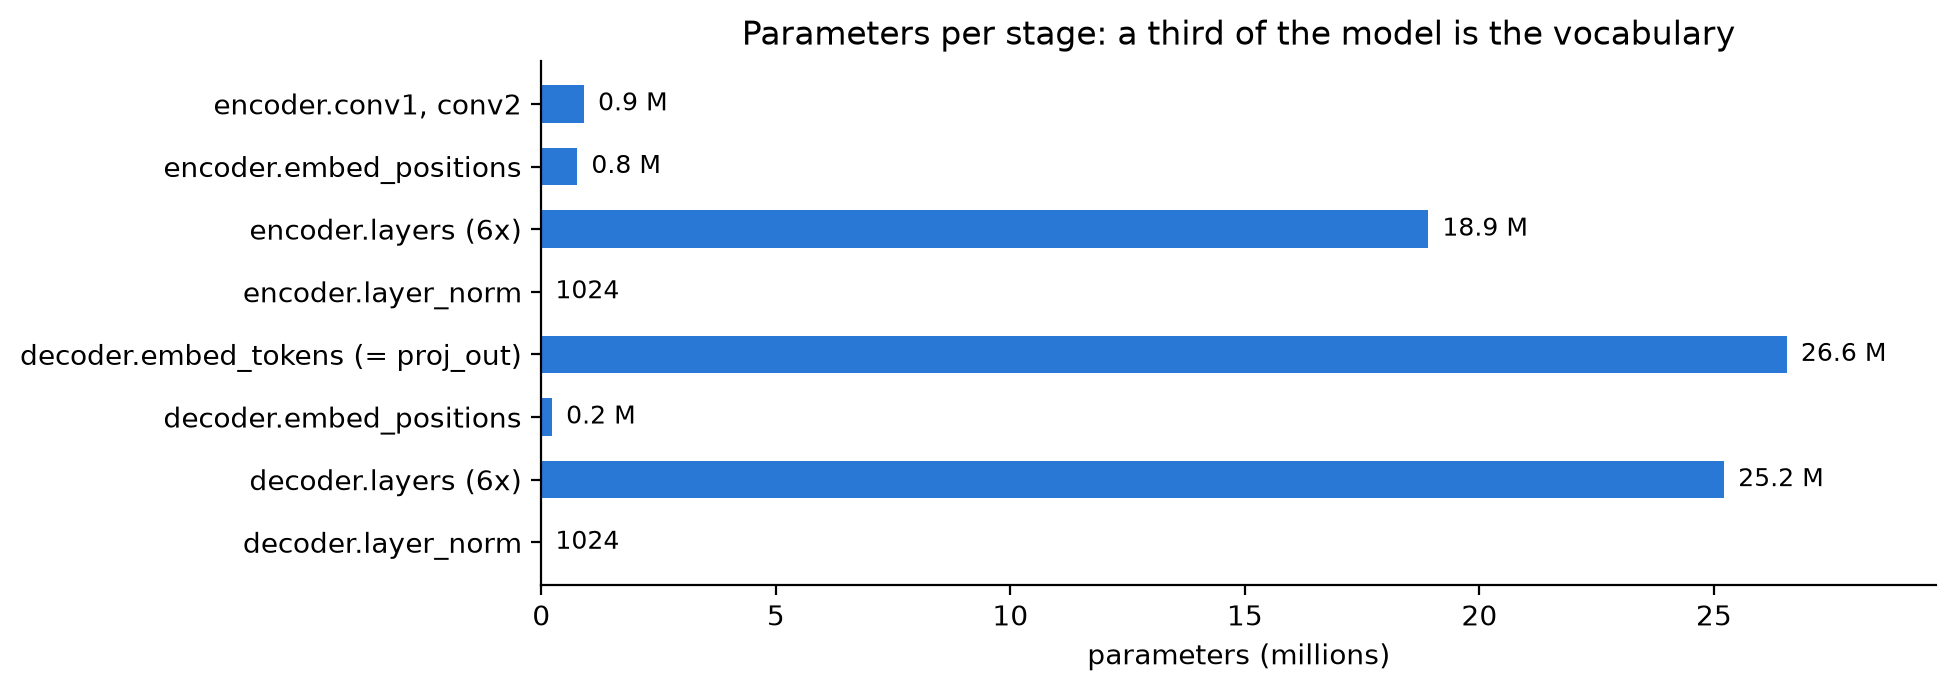

In [5]:
parts = table.drop(index="total")["parameters"][::-1] / 1e6
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(parts.index, parts.values, color=COLORS["conv"], height=0.6)
for y, v in enumerate(parts.values):
    ax.text(v + 0.3, y, f"{v:.1f} M" if v >= 0.1 else f"{v * 1e6:.0f}", va="center", fontsize=9)
ax.set(xlabel="parameters (millions)", title="Parameters per stage: a third of the model is the vocabulary",
       xlim=(0, parts.max() * 1.12))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

And grouped by the type of basic block (summed over all occurrences):

In [6]:
by_type, seen = {}, set()
for name, module in model.named_modules():
    own = [p for p in module.parameters(recurse=False) if id(p) not in seen]  # count the tied matrix once
    seen.update(id(p) for p in own)
    if own:
        kind = type(module).__name__
        kind = "Embedding" if isinstance(module, torch.nn.Embedding) else kind
        count, total = by_type.get(kind, (0, 0))
        by_type[kind] = (count + 1, total + sum(p.numel() for p in own))

pd.DataFrame(by_type, index=["modules", "parameters"]).T.sort_values("parameters", ascending=False)

,modules,parameters
Linear,96,44098560
Embedding,3,27552256
Conv1d,2,910336
LayerNorm,32,32768


Two thirds of the 73 M parameters are in `Linear` layers (attention projections and feed-forward networks),
one third in the embeddings — mostly the 51 865 × 512 token matrix. The convolutions are small (0.9 M): Whisper
doesn't learn its own filterbank from the waveform like wav2vec2 does, it starts from a fixed spectrogram.

## 2. Tracing shapes with forward hooks

A *forward hook* is a function PyTorch calls after a module's `forward`, with its inputs and outputs. We register one
on every basic block, run a recording through the model, and record the shapes.

The recording is the same one as in the Spectrogram and Wav2Vec2 notebooks: a 7.6 s clip from the assignment 3
validation set (16 kHz, with speech, music, and background sounds).

In [7]:
SAMPLE_RATE = 16_000
DATA = "danylo-ucla/speech-fraction/v1"
fs = s3fs.S3FileSystem()


def load_recording(segment, index):
    # The real length of each recording (before the zero padding) is in <segment>_y.parquet.
    samples = pd.read_parquet(f"s3://{DATA}/{segment}_y.parquet").samples[index]
    with fs.open(f"{DATA}/{segment}_x.npy", "rb", block_size=2**20) as f:
        np.lib.format.read_magic(f)
        (_, length), _, dtype = np.lib.format.read_array_header_1_0(f)
        row_bytes = length * dtype.itemsize
        f.seek(f.tell() + index * row_bytes)  # skip the header and the rows before this one
        row = np.frombuffer(f.read(row_bytes), dtype=dtype)
    return (row[:samples] / 32768).astype(np.float32)  # int16 -> float in [-1, 1]


audio = load_recording("validate", 4)
duration = len(audio) / SAMPLE_RATE
features = processor(audio, sampling_rate=SAMPLE_RATE, return_tensors="pt").input_features
print(f"{len(audio)} samples = {duration:.2f} s -> input_features {tuple(features.shape)} (batch, mel bins, frames)")

121349 samples = 7.58 s -> input_features (1, 80, 3000) (batch, mel bins, frames)


Whisper's input is not the waveform but its **log-mel spectrogram** (80 mel bins, one frame every 10 ms), always
padded to **30 s = 3000 frames**. Shorter recordings are padded with silence; longer ones are transcribed in 30 s windows.

The decoder also needs input: the tokens of the transcript. We let the model transcribe the recording first
(section 5 shows how this works), then run one forward pass with the start tokens followed by the transcript —
the same thing that happens during training ("teacher forcing").

In [8]:
tokenizer = processor.tokenizer
prompt = tokenizer.convert_tokens_to_ids(["<|startoftranscript|>", "<|en|>", "<|transcribe|>", "<|notimestamps|>"])
with torch.no_grad():
    generated = model.generate(features, language="en", task="transcribe")[0].tolist()
text_tokens = [t for t in generated if t not in prompt and t != tokenizer.eos_token_id]
decoder_input_ids = torch.tensor([prompt + text_tokens])
tokens = tokenizer.convert_ids_to_tokens(decoder_input_ids[0])
print(repr(tokenizer.decode(text_tokens)))
print(tokens)

' What are you doing? Nanna.'
['<|startoftranscript|>', '<|en|>', '<|transcribe|>', '<|notimestamps|>', 'ĠWhat', 'Ġare', 'Ġyou', 'Ġdoing', '?', 'ĠN', 'anna', '.']


In [9]:
BASIC = (torch.nn.Conv1d, torch.nn.LayerNorm, torch.nn.Linear, torch.nn.Embedding)


def is_traced(module: torch.nn.Module) -> bool:
    return isinstance(module, BASIC) or type(module).__name__ in ("GELUActivation", "WhisperAttention")


def first_tensor(x):
    while isinstance(x, (tuple, list)):
        x = x[0]
    return x


records = []


def make_hook(name):
    def hook(module, args, kwargs, output):
        x = args[0] if args else first_tensor(list(kwargs.values()))
        records.append({
            "module": name,
            "type": type(module).__name__,
            "input": tuple(first_tensor(x).shape),
            "output": tuple(first_tensor(output).shape),
            "parameters": 0 if type(module).__name__ == "WhisperAttention" else n_params(module),
        })
    return hook


handles = [m.register_forward_hook(make_hook(n.removeprefix("model.")), with_kwargs=True)
           for n, m in model.named_modules() if is_traced(m)]
with torch.no_grad():
    out = model(features, decoder_input_ids=decoder_input_ids, use_cache=False)
for h in handles:
    h.remove()

trace = pd.DataFrame(records)
len(trace)

164

The 6 encoder layers are identical, and so are the 6 decoder layers: check that each one produces exactly the same
sequence of shapes, then show only one of each (labelled `layers.*`).

In [10]:
trace["layer"] = trace["module"].str.extract(r"coder\.layers\.(\d+)\.")[0]
for part in ["encoder", "decoder"]:
    rows = trace[trace["module"].str.startswith(f"{part}.layers.")]
    per_layer = [g[["type", "input", "output", "parameters"]].reset_index(drop=True) for _, g in rows.groupby("layer")]
    assert len(per_layer) == 6 and all(p.equals(per_layer[0]) for p in per_layer), part

collapsed = trace[trace["layer"].isna() | (trace["layer"] == "0")].drop(columns="layer")
collapsed["module"] = collapsed["module"].str.replace(r"coder\.layers\.0\.", "coder.layers.*.", regex=True)

with pd.option_context("display.max_rows", 100, "display.max_colwidth", 60):
    display(collapsed.reset_index(drop=True))

,module,type,input,output,parameters
0,encoder.conv1,Conv1d,"(1, 80, 3000)","(1, 512, 3000)",123392
1,encoder.conv2,Conv1d,"(1, 512, 3000)","(1, 512, 1500)",786944
2,encoder.embed_positions,Embedding,"(1500,)","(1500, 512)",768000
3,encoder.layers.*.self_attn_layer_norm,LayerNorm,"(1, 1500, 512)","(1, 1500, 512)",1024
4,encoder.layers.*.self_attn.q_proj,Linear,"(1, 1500, 512)","(1, 1500, 512)",262656
5,encoder.layers.*.self_attn.k_proj,Linear,"(1, 1500, 512)","(1, 1500, 512)",262144
6,encoder.layers.*.self_attn.v_proj,Linear,"(1, 1500, 512)","(1, 1500, 512)",262656
7,encoder.layers.*.self_attn.out_proj,Linear,"(1, 1500, 512)","(1, 1500, 512)",262656
8,encoder.layers.*.self_attn,WhisperAttention,"(1, 1500, 512)","(1, 1500, 512)",0
9,encoder.layers.*.final_layer_norm,LayerNorm,"(1, 1500, 512)","(1, 1500, 512)",1024


Reading the table top to bottom is reading the forward pass: first the whole encoder, then the whole decoder.
The convolutions work on `(batch, channels, time)`, everything after them on `(batch, positions, features)`.

Things to notice:
- The encoder always produces **1500 vectors** (one per 20 ms of the 30 s window); the decoder has one per token ($L$, 12 here).
- In the decoder's `encoder_attn` (cross-attention), `q_proj` gets the decoder's $L$ vectors, while `k_proj` and `v_proj`
  get the encoder's 1500 vectors: this is the only connection between the two halves.
- `proj_out` turns each of the $L$ decoder vectors into 51 865 token scores.
- The GELUs right after the two convolutions are function calls (`F.gelu`), not modules, so the hooks don't see them;
  neither do the residual additions. The diagram below shows both.

### The architecture as a diagram

The same information as a picture: one box per basic block, colored by kind, with the output shape of each block
from the same kind of trace as above ($B$ = batch, $L$ = tokens). The 6 encoder and 6 decoder layers are each one bracket.
The arrows on the left of each column are residual connections: the input of a sub-layer is added to its output.

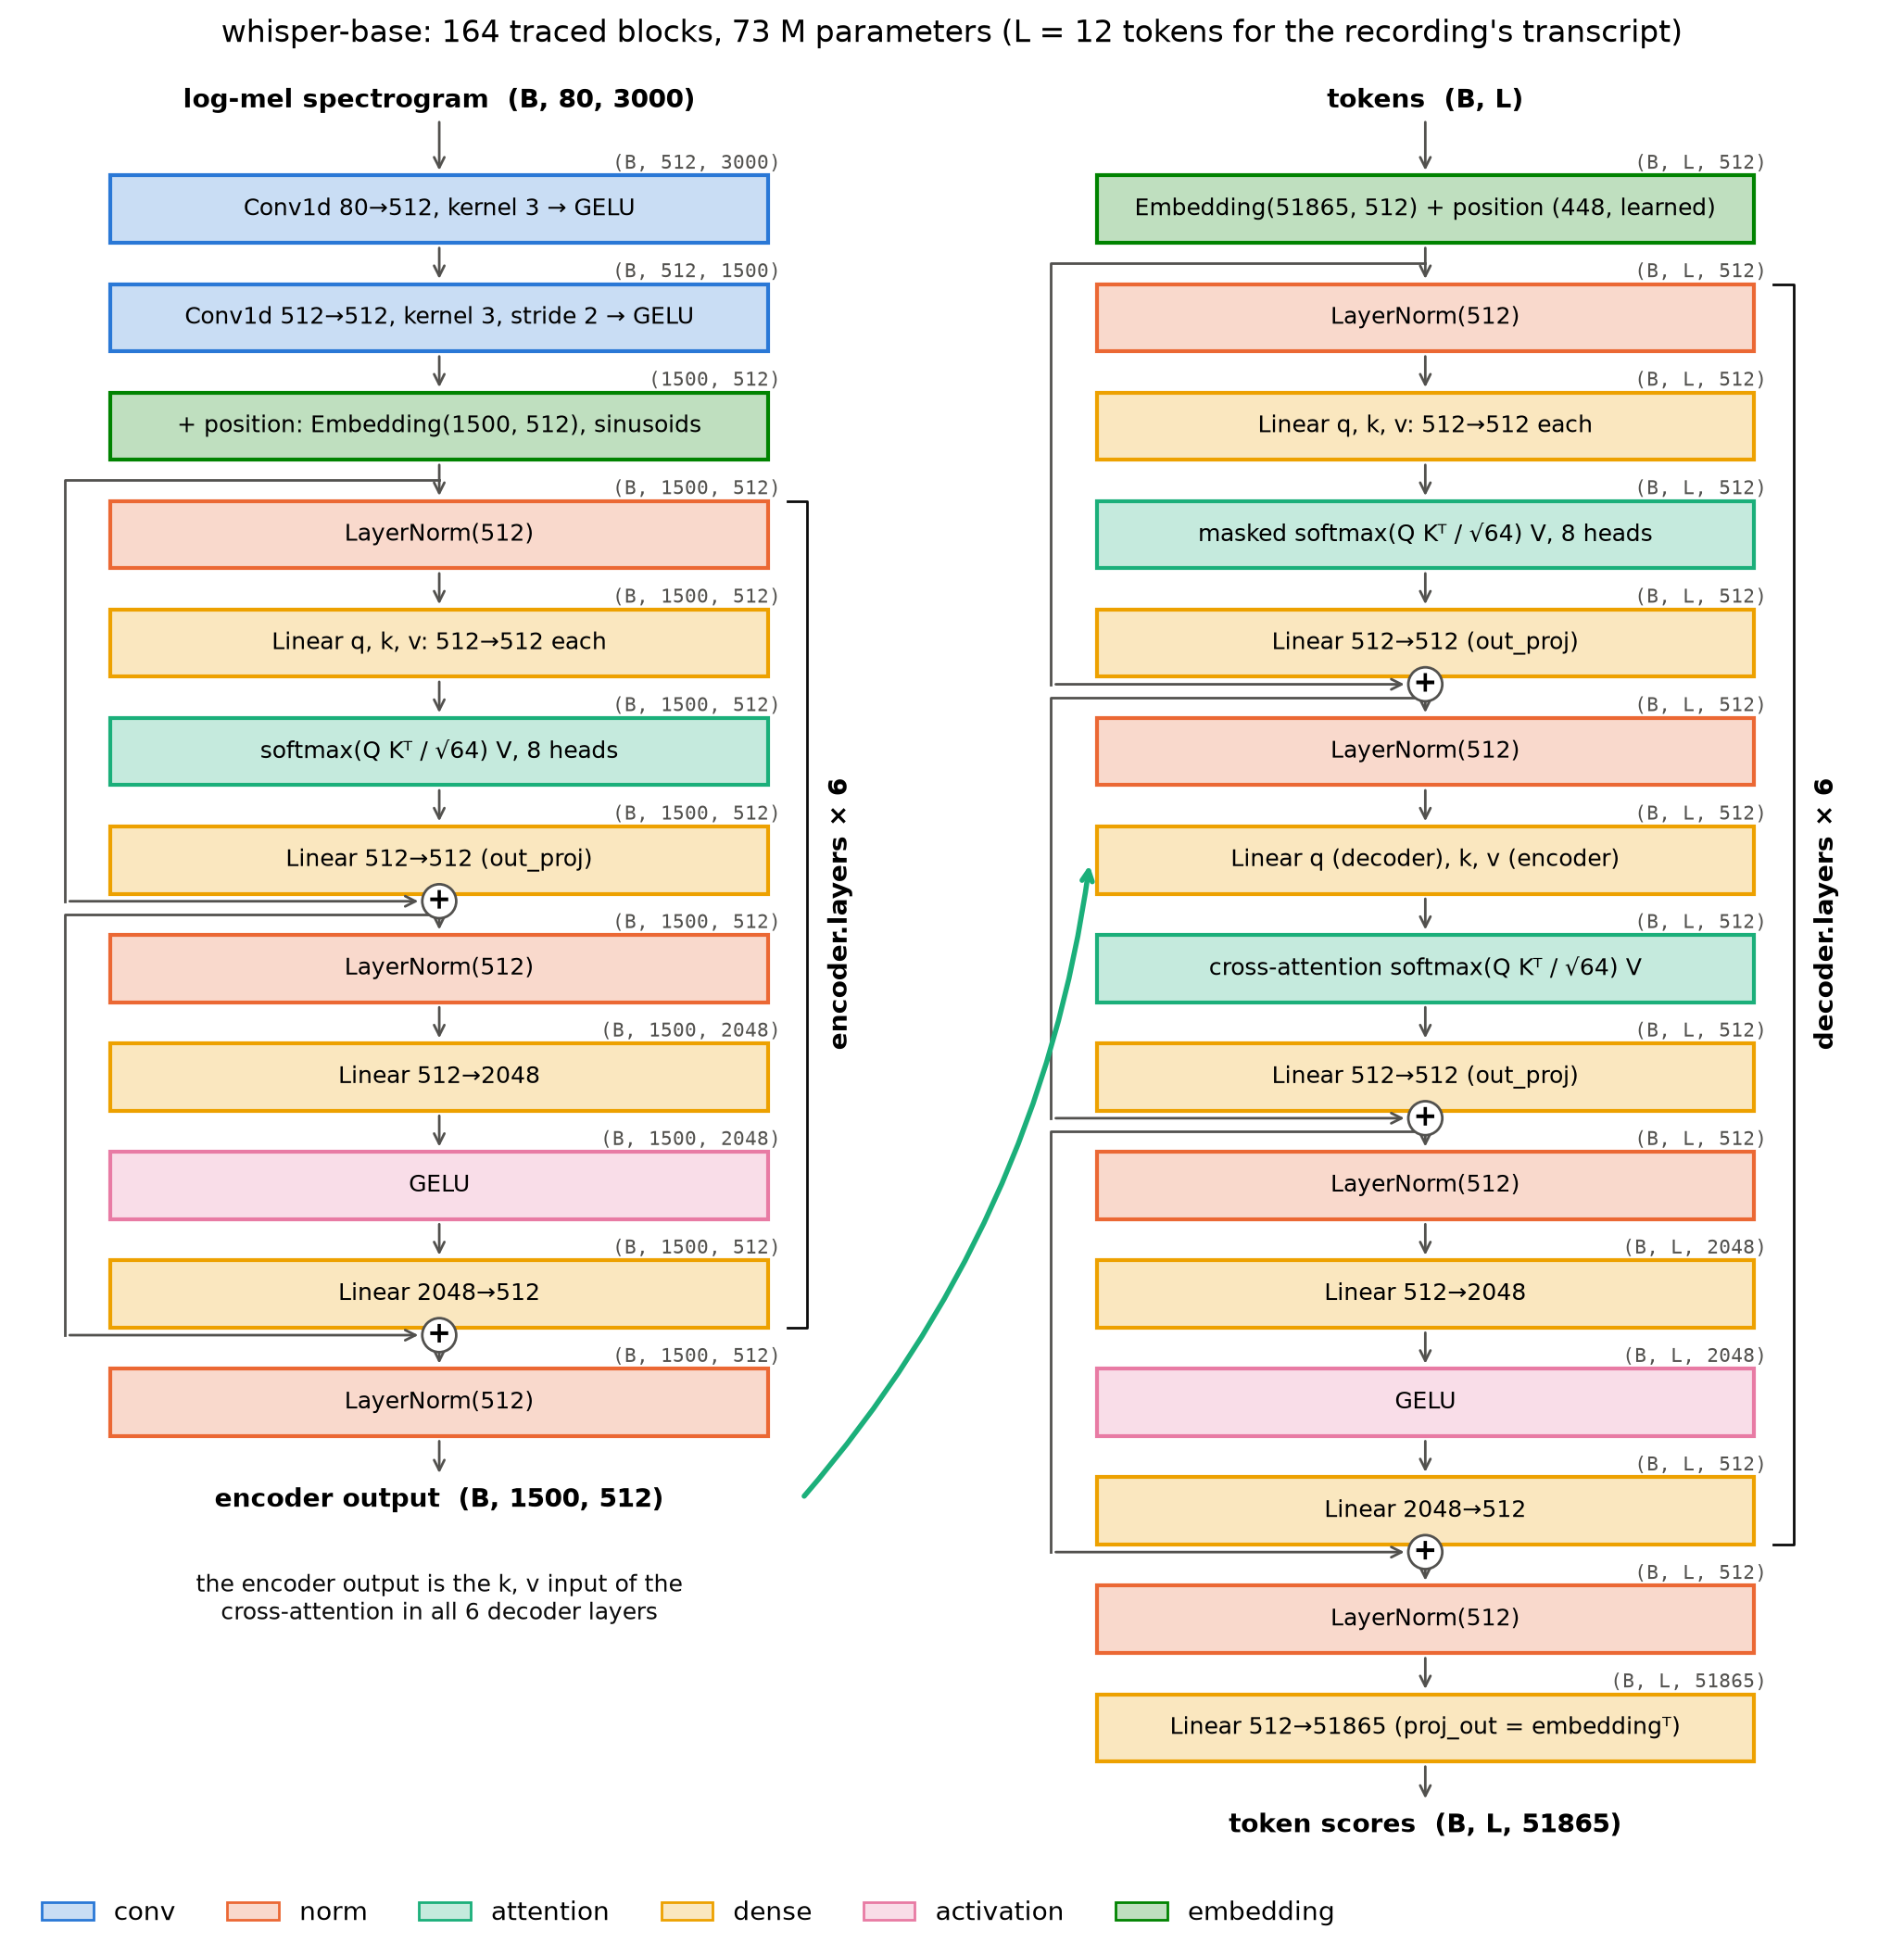

## 3. The front end: waveform → spectrogram → encoder frames

The feature extractor (`processor.feature_extractor`) is not part of the neural network: it computes a log-mel
spectrogram, exactly the steps of the Spectrogram notebook — an STFT with a 25 ms window (`n_fft` = 400 samples)
every 10 ms (`hop_length` = 160 samples), 80 mel filters, $\log_{10}$, then the values are clipped to at most 8
below the maximum and scaled by $(x + 4) / 4$.

Then two convolutions, both with padding 1 so that only the stride changes the length. A convolution with kernel
size $k$, stride $s$, and padding $p$ turns $L$ time steps into

$$L_\text{out} = \left\lfloor \frac{L + 2p - k}{s} \right\rfloor + 1$$

In [12]:
fe = processor.feature_extractor
rows = [{"layer": "STFT + mel", "in_channels": 1, "out_channels": fe.feature_size, "kernel": fe.n_fft, "stride": fe.hop_length,
         "output length": fe.nb_max_frames, "receptive field (samples)": fe.n_fft, "hop (samples)": fe.hop_length}]
length, receptive, jump = fe.nb_max_frames, fe.n_fft, fe.hop_length
for name in ["conv1", "conv2"]:
    conv = getattr(encoder, name)
    (k,), (s,), (p,) = conv.kernel_size, conv.stride, conv.padding
    length = (length + 2 * p - k) // s + 1
    receptive += (k - 1) * jump
    jump *= s
    rows.append({"layer": f"encoder.{name}", "in_channels": conv.in_channels, "out_channels": conv.out_channels,
                 "kernel": k, "stride": s, "output length": length, "receptive field (samples)": receptive,
                 "hop (samples)": jump})
pd.DataFrame(rows).set_index("layer")

,in_channels,out_channels,kernel,stride,output length,receptive field (samples),hop (samples)
layer,,,,,,,
STFT + mel,1,80,400,160,3000,400,160
encoder.conv1,80,512,3,1,3000,720,160
encoder.conv2,512,512,3,2,1500,1040,320


- The encoder frames are **20 ms** apart (320 samples), like wav2vec2's, and each sees **65 ms** of audio
  (1040 samples) — wider than wav2vec2's 25 ms, but the Transformer layers see the whole 30 s anyway.
- 30 s always gives 1500 encoder frames, however short the recording: here 7.6 s of audio and 22.4 s of padding.
  The padding is silence, i.e. a constant spectrogram, so after the convolutions every channel is constant there too.

The input of the encoder and the output of its convolutions for the whole 30 s window:

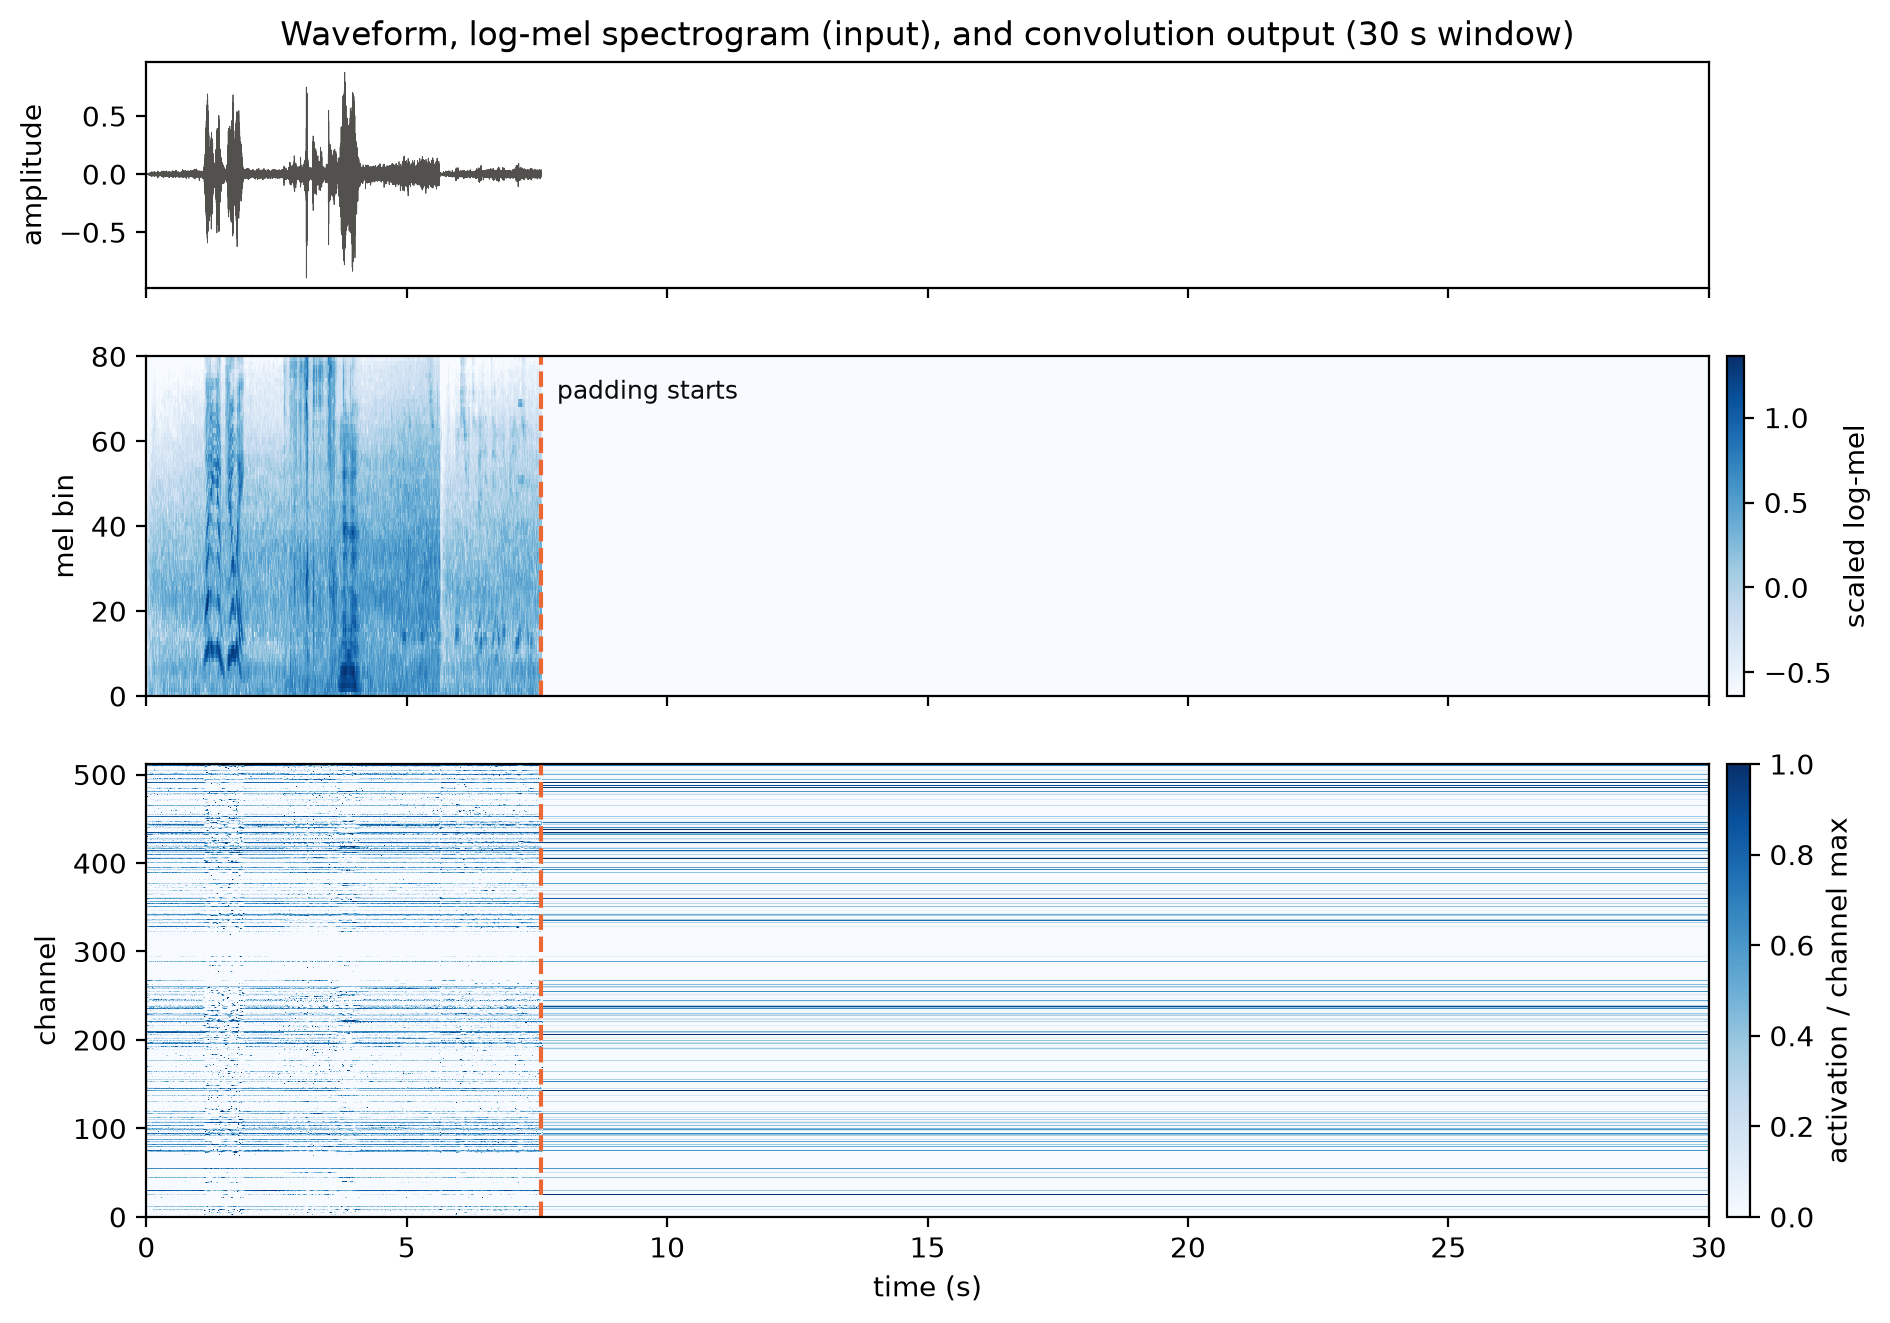

In [13]:
with torch.no_grad():
    stem = torch.nn.functional.gelu(encoder.conv2(torch.nn.functional.gelu(encoder.conv1(features))))[0].numpy()
scaled = np.maximum(stem, 0) / np.maximum(stem.max(axis=1, keepdims=True), 1e-6)  # each channel to its own maximum

fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.5, 2]})
axes[0].plot(np.arange(len(audio)) / SAMPLE_RATE, audio, lw=0.3, color="#52514e")
axes[0].set(ylabel="amplitude", xlim=(0, 30), title="Waveform, log-mel spectrogram (input), and convolution output (30 s window)")
mel = axes[1].imshow(features[0].numpy(), aspect="auto", origin="lower", cmap="Blues", extent=(0, 30, 0, 80),
                     interpolation="nearest")
axes[1].set(ylabel="mel bin")
fig.colorbar(mel, ax=axes[1], label="scaled log-mel", pad=0.01)
image = axes[2].imshow(scaled, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1, extent=(0, 30, 0, 512),
                       interpolation="nearest")
axes[2].set(xlabel="time (s)", ylabel="channel")
fig.colorbar(image, ax=axes[2], label="activation / channel max", pad=0.01)
fig.colorbar(image, ax=axes[0], pad=0.01).ax.set_visible(False)  # an invisible colorbar keeps the plots aligned
for ax in axes[1:]:
    ax.axvline(duration, color="#eb6834", lw=1.5, ls="--")
axes[1].text(duration + 0.3, 70, "padding starts", color="#0b0b0b", fontsize=9)
plt.show()

## 4. Encoder and decoder

### Positional embeddings

Attention by itself doesn't know the order of its inputs, so both halves add a position vector to each input vector:

- the encoder uses the **sinusoids** of the original Transformer (stored as an `Embedding`, but not learned):
  for position $t$ and $i = 0, \dots, 255$, channel $i$ is $\sin(t \, \omega_i)$ and channel $256 + i$ is
  $\cos(t \, \omega_i)$, with frequencies $\omega_i = 10000^{-i/255}$ from one cycle every $2\pi$ frames to one every
  $\approx 63\,000$ frames;
- the decoder **learns** one 512-d vector for each of its 448 positions (the longest transcript Whisper can write in one window).

In [14]:
t = torch.arange(config.max_source_positions)[:, None]
omega = 10000 ** (-torch.arange(256) / 255)
sinusoids = torch.cat([torch.sin(t * omega), torch.cos(t * omega)], dim=1)
print("encoder positions:", tuple(encoder.embed_positions.weight.shape),
      "match the sinusoid formula:", torch.allclose(encoder.embed_positions.weight, sinusoids, atol=1e-3))  # stored at lower precision
print("decoder positions:", tuple(decoder.embed_positions.weight.shape))

encoder positions: (1500, 512) match the sinusoid formula: True
decoder positions: (448, 512)


Both kinds make nearby positions similar and distant positions different. The cosine similarity between the
position vectors (first 448 positions of each):

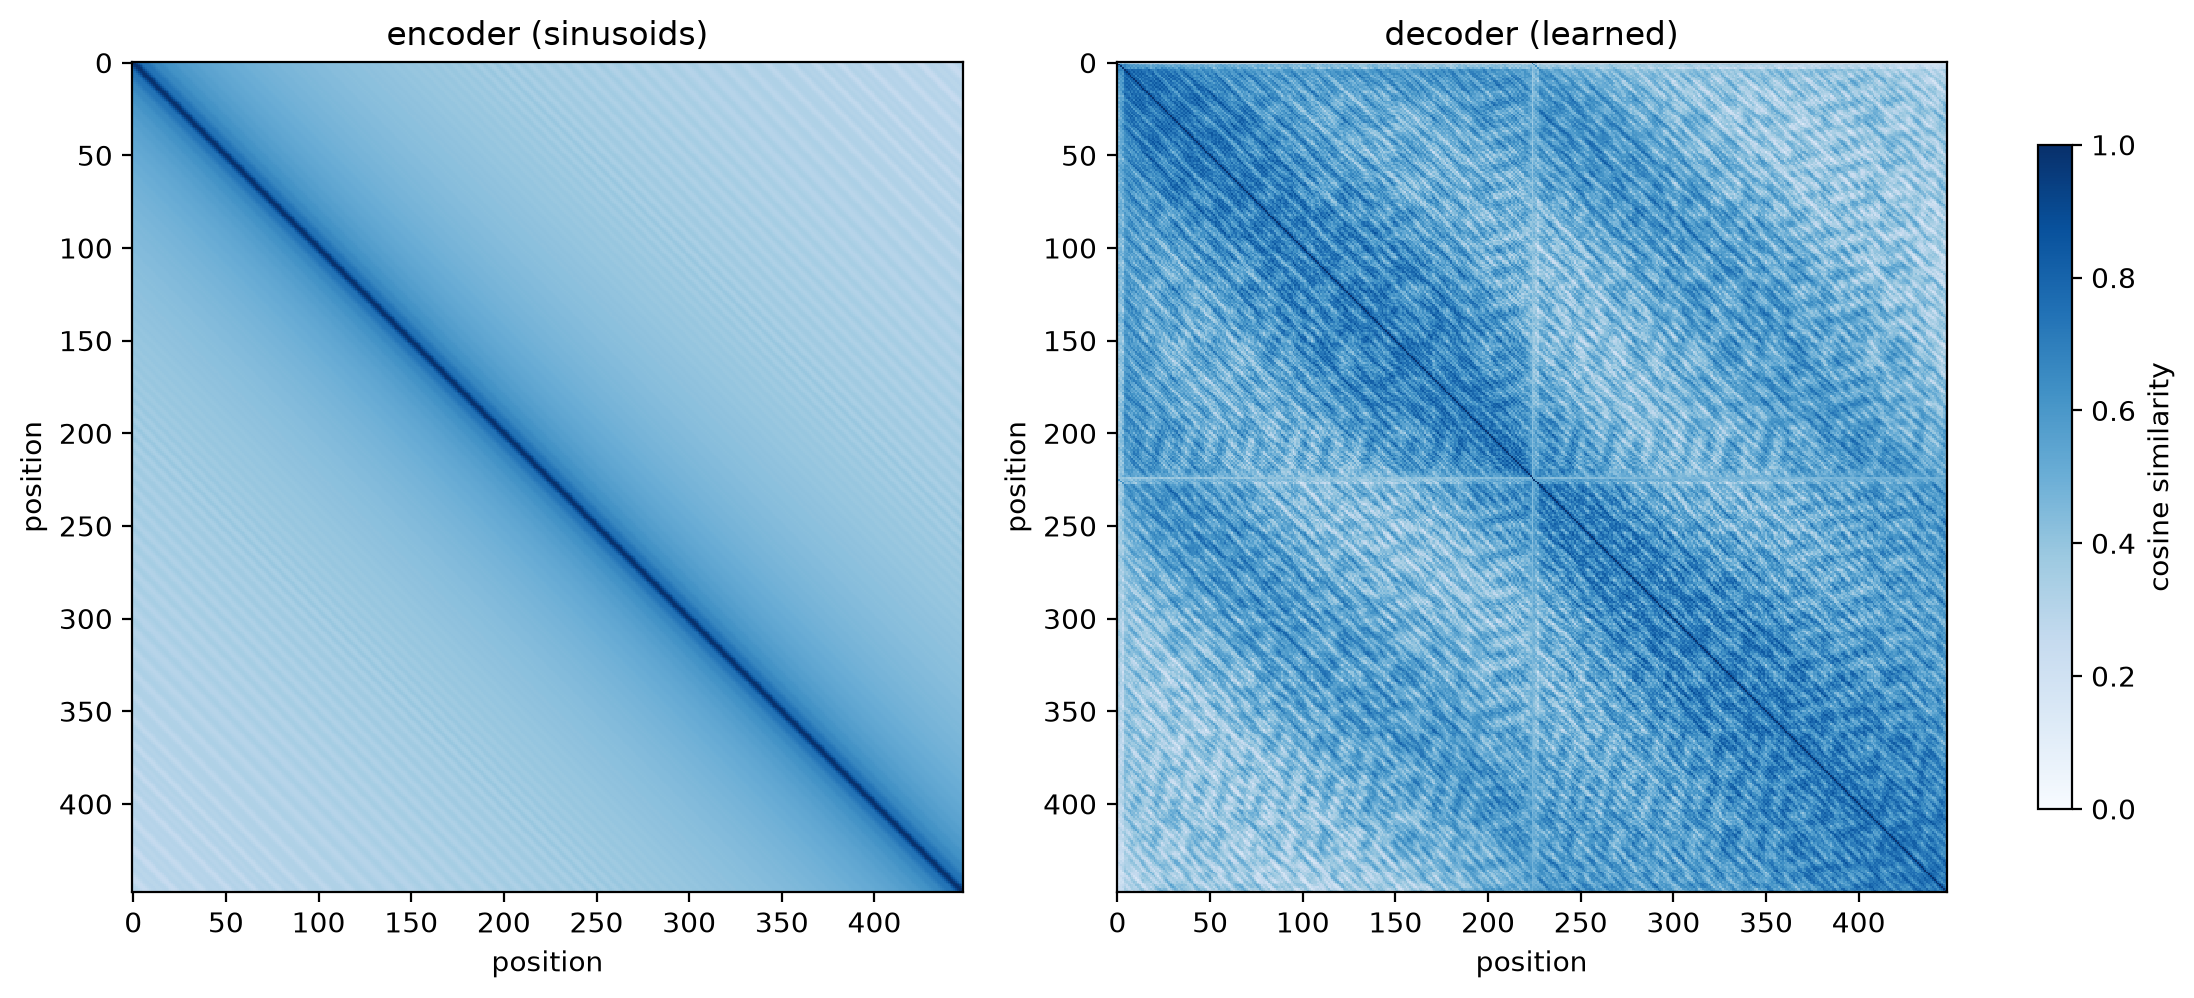

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
for ax, (name, weights) in zip(axes, [("encoder (sinusoids)", encoder.embed_positions.weight),
                                      ("decoder (learned)", decoder.embed_positions.weight)]):
    w = torch.nn.functional.normalize(weights.detach()[:448], dim=-1)
    image = ax.imshow((w @ w.T).numpy(), cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
    ax.set(title=name, xlabel="position", ylabel="position")
fig.colorbar(image, ax=axes, label="cosine similarity", shrink=0.8)
plt.show()

### The Transformer layers

Unlike `wav2vec2-base`, Whisper uses the **pre-norm** arrangement: each sub-layer normalizes its *input*, and
the residual path stays un-normalized (one final layer norm at the end of each stack). With $x$ of shape $(\cdot, 512)$:

$$\text{encoder layer:} \qquad h = x + \mathrm{SelfAttention}(\mathrm{LN}(x)) \qquad y = h + \mathrm{FFN}(\mathrm{LN}(h))$$

$$\text{decoder layer:} \qquad h = x + \mathrm{MaskedSelfAttention}(\mathrm{LN}(x)) \qquad g = h + \mathrm{CrossAttention}(\mathrm{LN}(h), e) \qquad y = g + \mathrm{FFN}(\mathrm{LN}(g))$$

with $\mathrm{FFN}(x) = W_2\,\mathrm{GELU}(W_1 x + b_1) + b_2$ (512 → 2048 → 512) and $e$ the encoder output.
Every attention has $8$ heads of $d = 512 / 8 = 64$ dimensions: for each head $i$,

$$\mathrm{head}_i = \mathrm{softmax}\!\left(\frac{Q_i K_i^\top}{\sqrt{d}} + M\right) V_i \qquad\qquad \mathrm{Attention} = [\mathrm{head}_1, \dots, \mathrm{head}_8]\, W^O$$

The three flavours differ only in where $Q$, $K$, $V$ come from and in the mask $M$:

| | queries from | keys and values from | mask $M$ |
|---|---|---|---|
| encoder self-attention | encoder frames | encoder frames | none: every frame sees all 1500 |
| decoder masked self-attention | tokens | tokens | $-\infty$ above the diagonal: token $j$ sees only tokens $\le j$ |
| decoder cross-attention | tokens | encoder output | none: every token sees all 1500 frames |

The mask makes the decoder *causal*: the prediction for position $j + 1$ can't peek at the tokens it should predict,
so one forward pass trains all positions at once. (`k_proj` has no bias: a bias on the keys would add the same
amount to all scores of a query, which the softmax cancels out.)

In [16]:
# Run the model once more, asking for the attention weights of every layer. The default attention
# implementation (PyTorch's fused scaled_dot_product_attention) doesn't return them, so switch to the plain one.
model.set_attn_implementation("eager")
with torch.no_grad():
    out = model(features, decoder_input_ids=decoder_input_ids, output_attentions=True, use_cache=False)
for name in ["encoder_attentions", "decoder_attentions", "cross_attentions"]:
    a = getattr(out, name)
    print(f"{name:20s} {len(a)} layers, each {tuple(a[0].shape)}")

encoder_attentions   6 layers, each (1, 8, 1500, 1500)
decoder_attentions   6 layers, each (1, 8, 12, 12)
cross_attentions     6 layers, each (1, 8, 12, 1500)


### What the encoder's attention heads do

Row $t$ of an attention map is the softmax distribution over which frames frame $t$ takes information from.
A few heads of the first, a middle, and the last encoder layer, cropped to the 7.6 s of real audio (each row also
spends some attention on the padding, not shown):

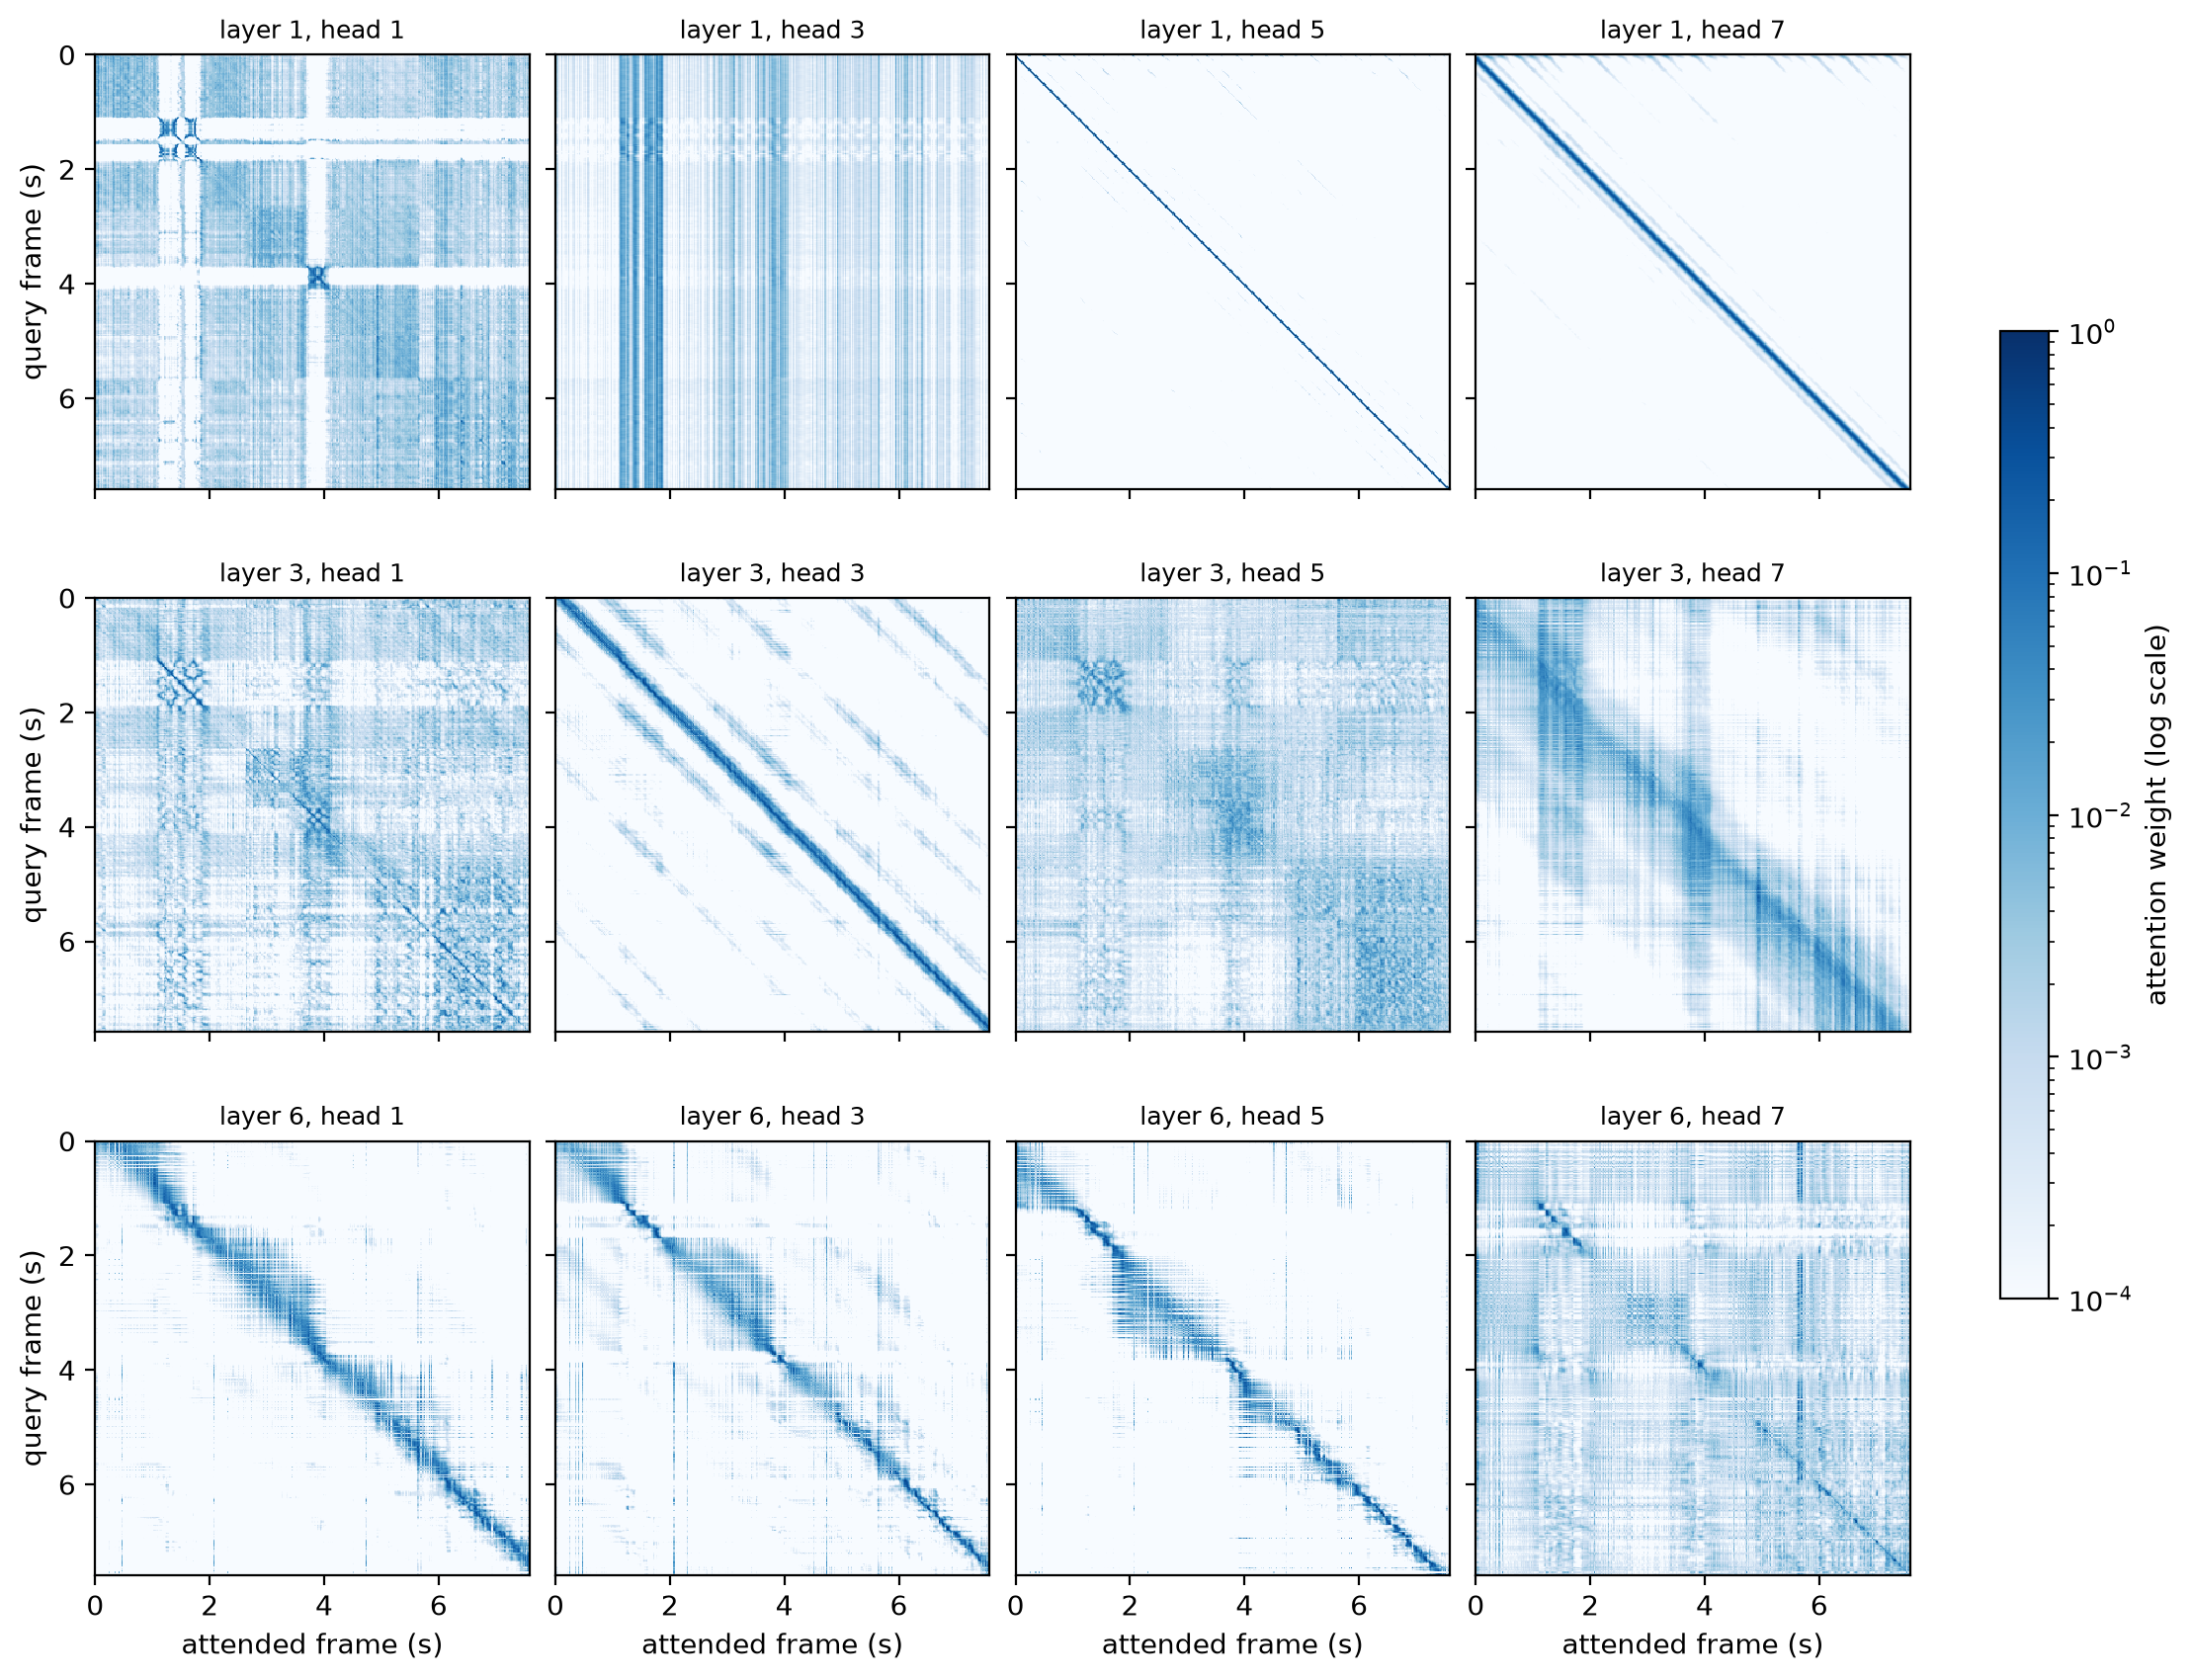

In [17]:
frames = int(duration / 0.02)  # encoder frames with real audio
layers, head_ids = [0, 2, 5], [0, 2, 4, 6]
fig, axes = plt.subplots(len(layers), len(head_ids), figsize=(11, 8.5), sharex=True, sharey=True, layout="constrained")
log_scale = matplotlib.colors.LogNorm(vmin=1e-4, vmax=1)
for row, layer_id in zip(axes, layers):
    for ax, head in zip(row, head_ids):
        image = ax.imshow(out.encoder_attentions[layer_id][0, head, :frames, :frames].numpy(), cmap="Blues",
                          norm=log_scale, extent=(0, duration, duration, 0), interpolation="nearest")
        ax.set_title(f"layer {layer_id + 1}, head {head + 1}", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("attended frame (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("query frame (s)")
fig.colorbar(image, ax=axes, label="attention weight (log scale)", shrink=0.6)
plt.show()

As in wav2vec2, some heads are local (a bright diagonal) and others gather information from particular events
of the whole recording (vertical stripes).

### What the decoder's attention heads do

The decoder's masked self-attention for the $L$ tokens (layer 6, averaged over heads): the upper triangle is
exactly zero because of the mask. Next to it, the **cross-attention**: for each token, where in the audio the decoder
looks. Whisper's authors found that a few specific heads (`generation_config.alignment_heads`) align tokens with
the time they are spoken; their average is plotted under the waveform, for the 7.6 s of real audio.

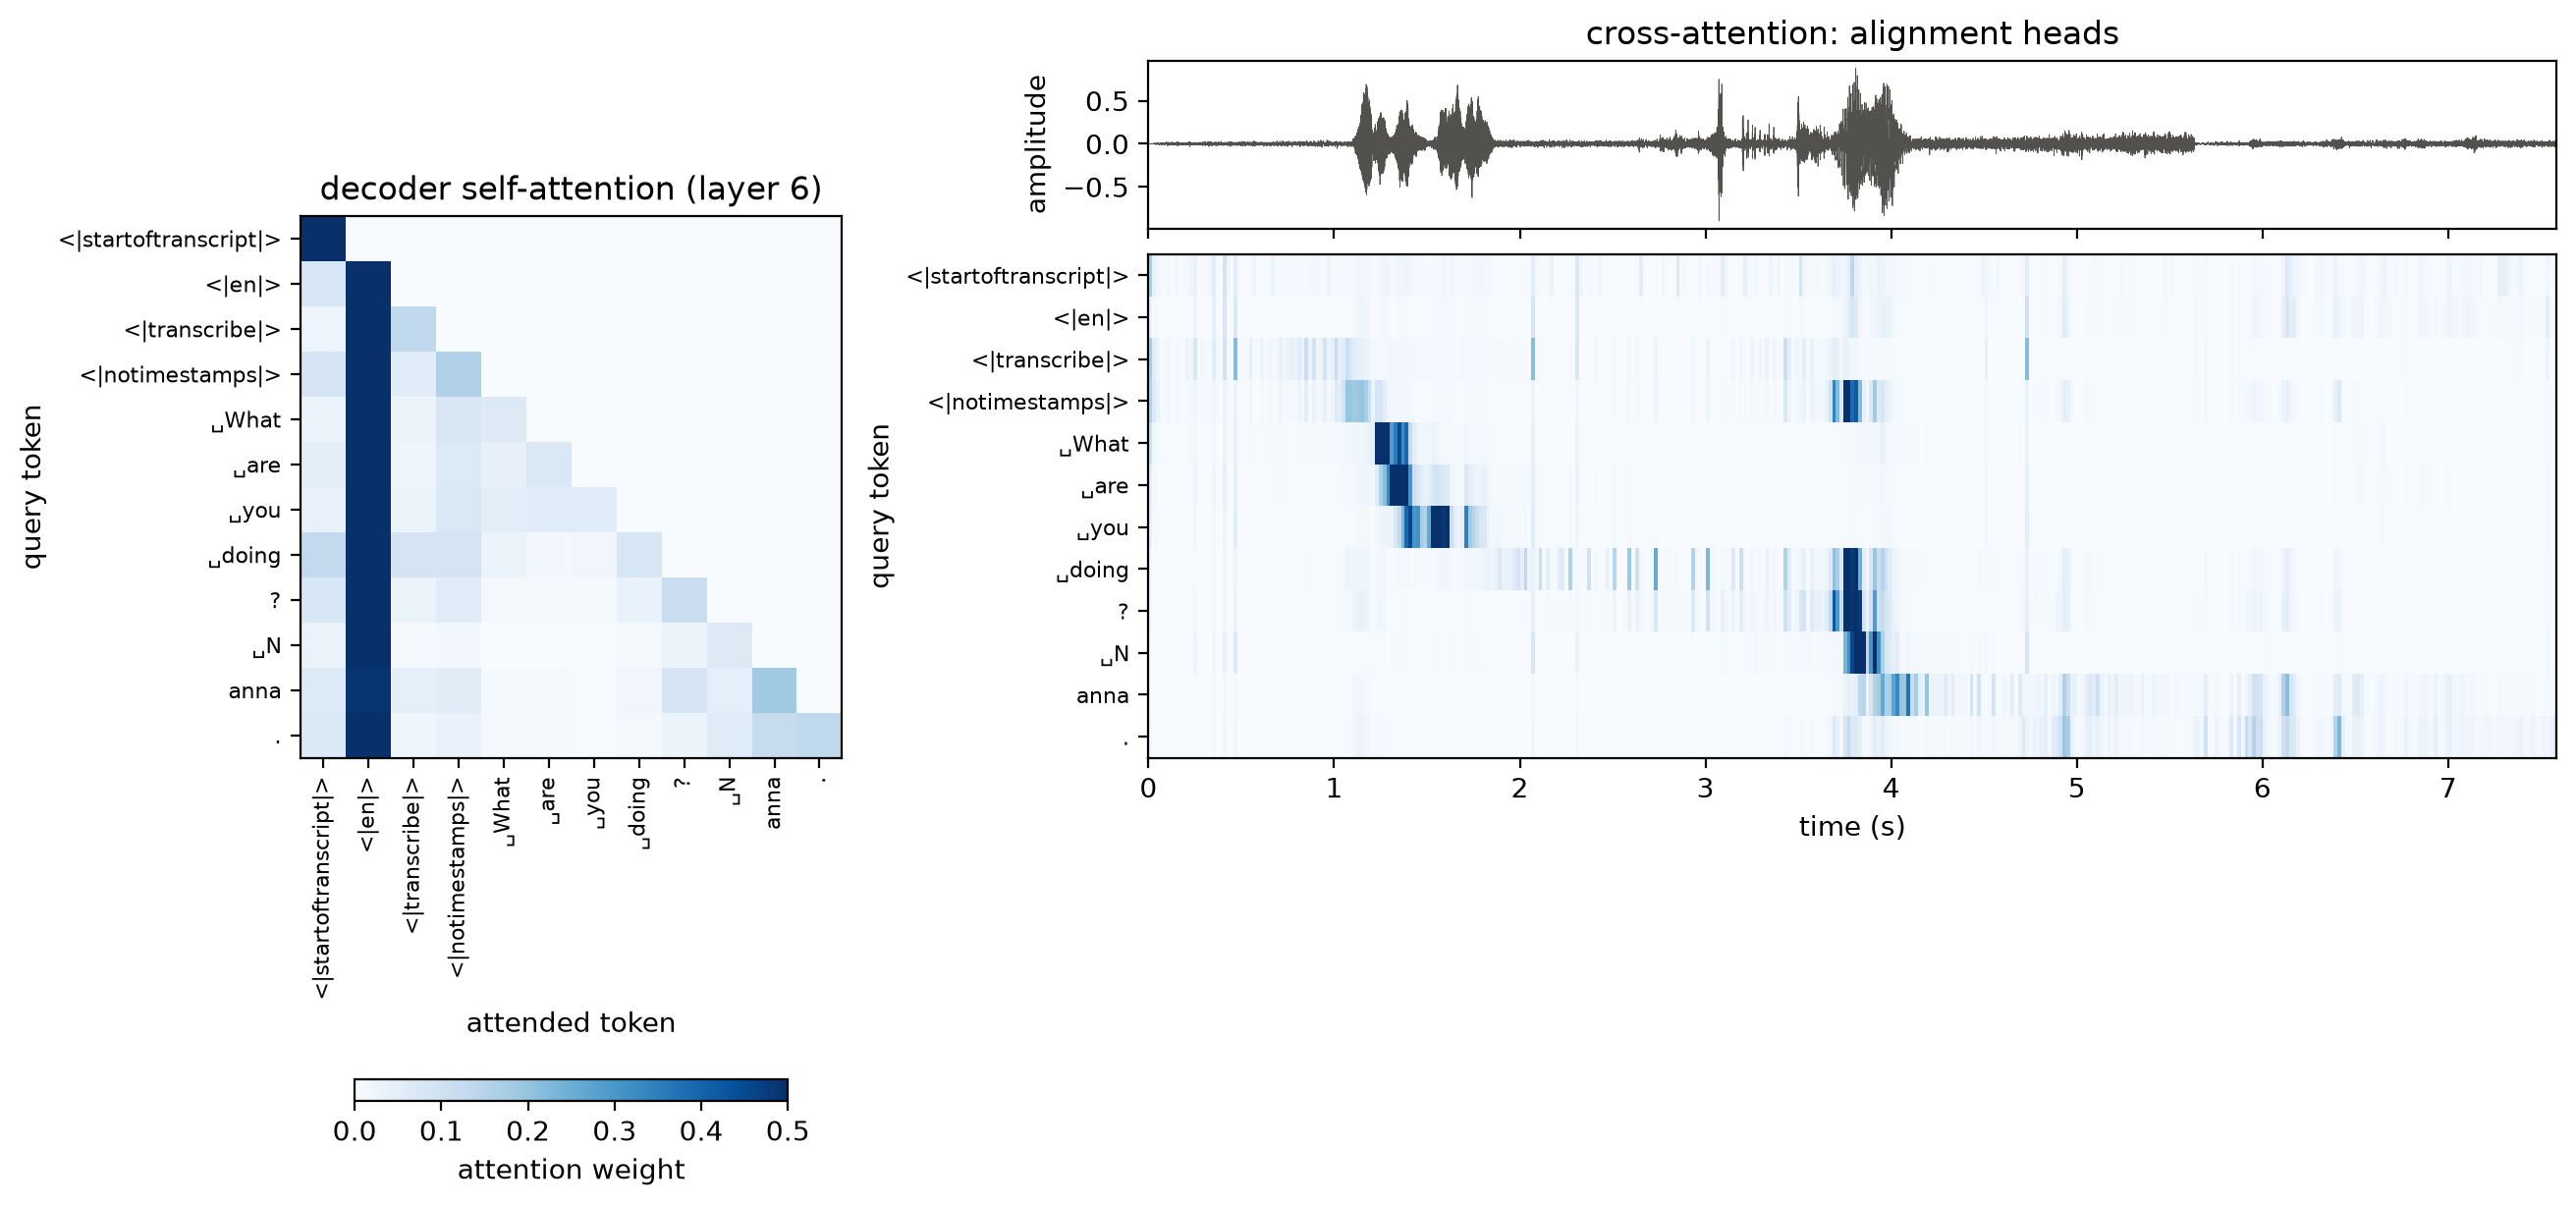

In [18]:
alignment_heads = model.generation_config.alignment_heads
cross = torch.stack([out.cross_attentions[layer][0, head] for layer, head in alignment_heads]).mean(dim=0)[:, :frames]
L = len(tokens)
labels = [t.replace("Ġ", "␣") for t in tokens]

fig = plt.figure(figsize=(13, 6), layout="constrained")
grid = fig.add_gridspec(2, 2, width_ratios=[1, 2.6], height_ratios=[1, 3])
self_ax = fig.add_subplot(grid[:, 0])
image = self_ax.imshow(out.decoder_attentions[-1][0].mean(dim=0).numpy(), cmap="Blues", vmin=0, vmax=0.5)
self_ax.set_xticks(range(L), labels, rotation=90, fontsize=8)
self_ax.set_yticks(range(L), labels, fontsize=8)
self_ax.set(title="decoder self-attention (layer 6)", xlabel="attended token", ylabel="query token")

wave_ax = fig.add_subplot(grid[0, 1])
wave_ax.plot(np.arange(len(audio)) / SAMPLE_RATE, audio, lw=0.3, color="#52514e")
wave_ax.set(xlim=(0, duration), title="cross-attention: alignment heads", ylabel="amplitude")
wave_ax.tick_params(labelbottom=False)
cross_ax = fig.add_subplot(grid[1, 1], sharex=wave_ax)
cross_ax.imshow(cross.numpy(), aspect="auto", cmap="Blues", extent=(0, duration, L - 0.5, -0.5),
                interpolation="nearest", vmin=0, vmax=np.quantile(cross.numpy(), 0.995))
cross_ax.set_yticks(range(L), labels, fontsize=8)
cross_ax.set(xlabel="time (s)", ylabel="query token")
fig.colorbar(image, ax=self_ax, label="attention weight", location="bottom", shrink=0.8)
plt.show()

The word tokens attend to the moment they are spoken: this is how Whisper produces word-level timestamps
(`pipeline(..., return_timestamps="word")`). The special tokens at the start carry no audio
content, and their attention is spread over the recording.

## 5. Speech recognition: clip in, text out

Whisper is trained for speech recognition directly, so no extra head is needed: `proj_out` already gives a score
for every token. The test clips are the same short phrases from the BSD10k collection as in the Wav2Vec2 notebook
(Freesound recordings, CC0 or CC BY). The expected text comes from each clip's Freesound description.

In [19]:
from IPython.display import Audio
from scipy.io import wavfile
from scipy.signal import resample_poly
from transformers import pipeline

BSD = "danylo-ucla/bsd/bsd10k"
phrases = {  # Freesound sound id -> what is said, according to the clip's description
    405261: "for hope and dreams",
    209413: "look over there",
    240674: "you have been denied",
    200381: "gravy is a meat extender",
    369908: "audio signal processing for music applications",
}
metadata = pd.read_csv(f"s3://{BSD}/metadata/BSD10k_metadata.csv").set_index("sound_id").loc[list(phrases)]
metadata[["title", "uploader", "license"]]

,title,uploader,license
sound_id,,,
405261,ZierotaHopeDreams2.wav,mousepatrol,http://creativecommons.org/publicdomain/zero/1.0/
209413,"Look, Over There.flac",qubodup,https://creativecommons.org/licenses/by/4.0/
240674,You have been denied,Zajo,http://creativecommons.org/publicdomain/zero/1.0/
200381,gravy is a meat extender.wav,cognito perceptu,http://creativecommons.org/publicdomain/zero/1.0/
369908,male speech,germanio,http://creativecommons.org/publicdomain/zero/1.0/


In [20]:
def load_clip(sound_id):
    # The clips are 44.1 kHz 16-bit WAV files; Whisper needs 16 kHz.
    with fs.open(f"{BSD}/audio/{sound_id}.wav", "rb") as f:
        rate, samples = wavfile.read(f)
    samples = samples.reshape(len(samples), -1).mean(axis=1) / 32768  # stereo -> mono, int16 -> [-1, 1]
    return resample_poly(samples, SAMPLE_RATE, rate).astype(np.float32)


clip = load_clip(405261)
print(f"{len(clip)} samples = {len(clip) / SAMPLE_RATE:.2f} s")
Audio(clip, rate=SAMPLE_RATE)

28793 samples = 1.80 s


### The pipeline

`transformers.pipeline` bundles the preprocessing (log-mel spectrogram, padding to 30 s), the model, the decoding
loop, and turning tokens back into text:

In [21]:
asr = pipeline("automatic-speech-recognition", model="openai/whisper-base")
asr(clip)

{'text': ' for hope and dreams.'}

### Under the hood: tokens

The decoder writes **tokens**, not characters: a byte-pair encoding (BPE) vocabulary of 50 257 text pieces
(the same as GPT-2: frequent words are one token, rare words are split; `Ġ` marks a leading space),
plus 1 608 special tokens that tell the decoder what to do:

In [22]:
print(tokenizer.tokenize(" for hope and dreams."), tokenizer.tokenize(" Gravy is a meat extender."))
special = tokenizer.convert_ids_to_tokens(range(tokenizer.eos_token_id, config.vocab_size))
languages = [t for t in special if t in model.generation_config.lang_to_id]
print(f"{len(special)} special tokens:", special[:4], f"{len(languages)} languages", languages[:5], "...",
      special[1 + len(languages):9 + len(languages)], "timestamps", special[-1501:-1499], "...", special[-1:])

['Ġfor', 'Ġhope', 'Ġand', 'Ġdreams', '.'] ['ĠGra', 'vy', 'Ġis', 'Ġa', 'Ġmeat', 'Ġext', 'ender', '.']
1608 special tokens: ['<|endoftext|>', '<|startoftranscript|>', '<|en|>', '<|zh|>'] 99 languages ['<|en|>', '<|zh|>', '<|de|>', '<|es|>', '<|ru|>'] ... ['<|su|>', '<|translate|>', '<|transcribe|>', '<|startoflm|>', '<|startofprev|>', '<|nocaptions|>', '<|notimestamps|>', '<|0.00|>'] timestamps ['<|0.00|>', '<|0.02|>'] ... ['<|30.00|>']


Every transcript starts with a fixed **prompt**: `<|startoftranscript|>`, a language token, a task token
(`<|transcribe|>` or `<|translate|>` into English), and `<|notimestamps|>` (or time tokens interleaved with the text).
Training on many languages and tasks at once in one model is done just by changing these tokens.

### Language detection

The token after `<|startoftranscript|>` is the language: one decoder step, restricted to the 99 language tokens.

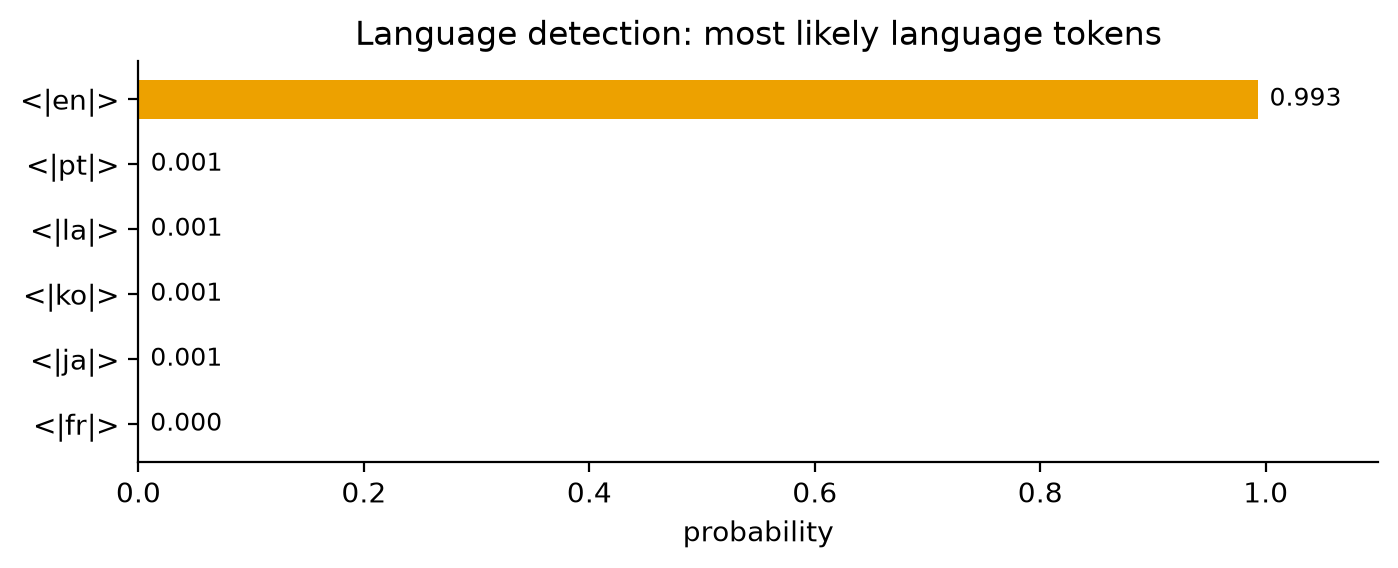

In [23]:
clip_features = processor(clip, sampling_rate=SAMPLE_RATE, return_tensors="pt").input_features
sot = tokenizer.convert_tokens_to_ids("<|startoftranscript|>")
with torch.no_grad():
    encoder_output = encoder(clip_features).last_hidden_state                     # run the encoder once
    logits = model(encoder_outputs=(encoder_output,), decoder_input_ids=torch.tensor([[sot]])).logits[0, -1]
language_ids = list(model.generation_config.lang_to_id.values())
language_probs = pd.Series(logits[language_ids].softmax(dim=-1).numpy(),
                           index=tokenizer.convert_ids_to_tokens(language_ids)).sort_values()[-6:]

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(language_probs.index, language_probs.values, color=COLORS["dense"], height=0.6)
for y, v in enumerate(language_probs.values):
    ax.text(v + 0.01, y, f"{v:.3f}", va="center", fontsize=9)
ax.set(xlabel="probability", xlim=(0, 1.1), title="Language detection: most likely language tokens")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Greedy decoding

The decoder is **autoregressive**: it predicts one token, appends it to its input, and runs again, until it predicts
`<|endoftext|>`. The encoder runs only once; its output is reused at every step through the cross-attention.

*Greedy* decoding takes the most likely token at each step. `model.generate` additionally never allows a fixed list of
tokens (`suppress_tokens`: mostly symbols, and special tokens that make no sense in the middle of a transcript), nor a
blank or end of text as the very first token (`begin_suppress_tokens`). With the same rules, our loop gives the same
tokens as `generate`.

In [24]:
language = language_probs.index[-1]
tokens_so_far = tokenizer.convert_tokens_to_ids(["<|startoftranscript|>", language, "<|transcribe|>", "<|notimestamps|>"])
n_prompt = len(tokens_so_far)
suppress = model.generation_config.suppress_tokens
begin_suppress = model.generation_config.begin_suppress_tokens
steps = []

with torch.no_grad():
    while tokens_so_far[-1] != tokenizer.eos_token_id and len(tokens_so_far) < config.max_target_positions:
        logits = model(encoder_outputs=(encoder_output,), decoder_input_ids=torch.tensor([tokens_so_far])).logits[0, -1]
        logits[suppress] = -float("inf")
        if len(tokens_so_far) == n_prompt:
            logits[begin_suppress] = -float("inf")
        probs = logits.softmax(dim=-1)
        top = probs.topk(3)
        steps.append({f"#{k + 1}": f"{tokenizer.convert_ids_to_tokens(int(i))}  {p:.2f}"
                      for k, (p, i) in enumerate(zip(top.values, top.indices))})
        tokens_so_far.append(int(top.indices[0]))                                # greedy: the most likely token

    reference = model.generate(clip_features, language=language, task="transcribe")[0].tolist()
ours = tokens_so_far[n_prompt:]
print(repr(tokenizer.decode(ours, skip_special_tokens=True)))
# generate returns the text tokens only (without the prompt and <|endoftext|>)
special_ids = set(tokens_so_far[:n_prompt]) | {tokenizer.eos_token_id}
print("same as generate:", [t for t in reference if t not in special_ids] == [t for t in ours if t not in special_ids])

' for hope and dreams.'
same as generate: True


The three most likely tokens at each step, with their probabilities (the first column is the one chosen):

In [25]:
pd.DataFrame(steps).rename_axis("step")

,#1,#2,#3
step,,,
0,Ġfor 0.82,ĠFor 0.07,Ġand 0.01
1,Ġhope 0.91,Ġhelp 0.04,ĠHope 0.04
2,Ġand 0.94,", 0.03",<|endoftext|> 0.01
3,Ġdreams 1.00,Ġdream 0.00,<|endoftext|> 0.00
4,. 0.89,<|endoftext|> 0.07,"."" 0.01"
5,<|endoftext|> 0.99,ĠYou 0.00,Ġyou 0.00


In practice, `generate` (and the pipeline) can also use **beam search** (`num_beams`): it keeps the several most
likely partial transcripts instead of only the best one, and returns the most likely complete one.

### More clips

In [26]:
results = pd.DataFrame({
    "expected": phrases,
    "recognized": {sound_id: asr(load_clip(sound_id))["text"].strip() for sound_id in phrases},
})
results

,expected,recognized
405261,for hope and dreams,for hope and dreams.
209413,look over there,Look! Over there!
240674,you have been denied,You have been denied.
200381,gravy is a meat extender,Gravy is a meat extender.
369908,audio signal processing for music applications,Or you see another processing for music applic...


Unlike wav2vec2 with CTC, which picks every character from the sound alone, Whisper's decoder is a **language
model** conditioned on the audio: each token is predicted from the audio *and* the previous tokens. Spelling,
capitalization, and punctuation come out right, and "gravy is a meat extender" — which wav2vec2 heard as "grivy is a
made extender" — is no longer a problem. It also helps that Whisper was trained on 680 000 hours of varied audio
rather than 960 hours of audiobooks. The flip side of a language model: when the audio is unclear, it produces
fluent but wrong text ("audio signal processing").